# Adverse-Weather Disaster Hazard Detection: YOLOv8 Training
Runtime: **Runtime > Change runtime type > T4 GPU**.

Classes: `0 blocked_road`, `1 debris`, `2 damaged_building`

Expected zip layout (synthetic and real):
```
dataset/
  images/{train,val,test}/*.jpg
  labels/{train,val,test}/*.txt
```
Upload `synthetic.zip` and `real.zip` to `MyDrive/adverse_weather/` first.

In [ ]:
!nvidia-smi
!pip install -q ultralytics

Sat Oct 24 17:27:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, zipfile, yaml, shutil
BASE = '/content/drive/MyDrive/adverse_weather'   # change if your folder differs
OUT  = f'{BASE}/runs'                              # results saved to Drive
os.makedirs(OUT, exist_ok=True)
NAMES = {0:'blocked_road', 1:'debris', 2:'damaged_building'}
SEED = 42
IMGSZ = 640

Mounted at /content/drive


In [ ]:
def prepare(zip_name, folder):
    dest = f'/content/{folder}'
    if not os.path.exists(dest):
        with zipfile.ZipFile(f'{BASE}/{zip_name}') as z:
            z.extractall(dest)
    # find the folder that contains images/ (handles an extra top-level folder)
    root = dest
    for r, dirs, _ in os.walk(dest):
        if 'images' in dirs and 'labels' in dirs:
            root = r; break
    cfg = {'path': root, 'train':'images/train', 'val':'images/val',
           'test':'images/test', 'names': NAMES}
    yml = f'/content/{folder}.yaml'
    yaml.safe_dump(cfg, open(yml,'w'))
    extensions = {'.png', '.jpg', '.jpeg', '.bmp', '.webp'}

    for s in ['train', 'val', 'test']:
        image_dir = os.path.join(root, 'images', s)
        label_dir = os.path.join(root, 'labels', s)

        images = []
        for dirpath, _, filenames in os.walk(image_dir):
            for filename in filenames:
                if os.path.splitext(filename)[1].lower() in extensions:
                    images.append(os.path.join(dirpath, filename))

        missing = []
        for image in images:
            rel = os.path.relpath(image, image_dir)
            label = os.path.join(label_dir, os.path.splitext(rel)[0] + '.txt')
            if not os.path.isfile(label):
                missing.append(rel)

        if missing:
            raise ValueError(
                f"{folder}/{s}: {len(missing)} images have no matching label; "
                f"examples: {missing[:5]}"
            )

        print(folder, s, len(images), 'images')

    return yml

SYN_YAML = prepare('synthetic.zip', 'synthetic')

REAL_YAML = prepare('real.zip', 'real')

synthetic train 948 images
synthetic val 134 images
synthetic test 118 images
real train 706 images
real val 149 images
real test 146 images


## 1. Baseline: train on synthetic data

In [ ]:
from ultralytics import YOLO

model = YOLO('yolov8s.pt')
model.train(data=SYN_YAML, epochs=50, imgsz=IMGSZ, batch=16, seed=SEED,
            project=OUT, name='synthetic', exist_ok=True)

shutil.copy(f'{OUT}/synthetic/weights/best.pt', f'{BASE}/synthetic_best.pt')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/synthetic.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=

'/content/drive/MyDrive/adverse_weather/synthetic_best.pt'

In [ ]:
# Synthetic test-split metrics (class 2 has no synthetic examples, so it is ignored automatically)
m = YOLO(f'{BASE}/synthetic_best.pt')
r = m.val(data=SYN_YAML, split='test', imgsz=IMGSZ)
print('P', r.box.mp, 'R', r.box.mr, 'mAP50', r.box.map50, 'mAP50-95', r.box.map)

Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2828.4±235.4 MB/s, size: 1842.8 KB)
val: Scanning /content/synthetic/hazard_dataset/labels/test/clear.cache... 118 images, 9 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 118/118 35.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.4it/s 5.8s
                   all        118        750       0.76      0.648      0.675      0.379
          blocked_road        109        109      0.775       0.78      0.791      0.497
                debris        109        641      0.744      0.516      0.558      0.261
Speed: 3.5ms preprocess, 7.8ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to /content/runs/detect/val-2
P 0.7596572884026143 R 0.6480985844938385 mAP50 0.6747490257799121 mAP50-95 

In [ ]:
import shutil
shutil.copytree('/content/runs/detect/val-2', f'{OUT}/synthetic_test_val', dirs_exist_ok=True)

'/content/drive/MyDrive/adverse_weather/runs/synthetic_test_val'

## 2. Fine-tune on real data (start from synthetic weights)

In [ ]:
REAL_YAML = prepare('real.zip', 'real')

ft = YOLO(f'{BASE}/synthetic_best.pt')
ft.train(data=REAL_YAML, epochs=30, imgsz=IMGSZ, batch=16, lr0=0.001, seed=SEED,
         project=OUT, name='finetuned', exist_ok=True)
shutil.copy(f'{OUT}/finetuned/weights/best.pt', f'{BASE}/finetuned_best.pt')

real train 706 images
real val 149 images
real test 146 images
Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/real.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/adverse_weather/synthetic_best.pt, momentum=0.9

'/content/drive/MyDrive/adverse_weather/finetuned_best.pt'

## 3. Real-only baseline (shows whether synthetic data helped)

In [ ]:
ro = YOLO('yolov8s.pt')
ro.train(data=REAL_YAML, epochs=50, imgsz=IMGSZ, batch=16, seed=SEED,
         project=OUT, name='real_only', exist_ok=True)
shutil.copy(f'{OUT}/real_only/weights/best.pt', f'{BASE}/real_only_best.pt')

Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/real.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=real_only, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto,

'/content/drive/MyDrive/adverse_weather/real_only_best.pt'

## 4. Evaluate all models on the same held-out real test set

In [ ]:
import pandas as pd

def evaluate(weights, label):
    r = YOLO(weights).val(data=REAL_YAML, split='test', imgsz=IMGSZ, plots=True)
    p, rc = r.box.mp, r.box.mr
    f1 = 2*p*rc/(p+rc) if (p+rc) else 0
    return {'Model':label, 'Precision':round(p,3), 'Recall':round(rc,3),
            'F1':round(f1,3), 'mAP@0.50':round(r.box.map50,3),
            'mAP@0.50:0.95':round(r.box.map,3)}

rows = [
    evaluate(f'{BASE}/synthetic_best.pt', 'Synthetic-trained YOLOv8s'),
    evaluate(f'{BASE}/finetuned_best.pt', 'Synthetic + real fine-tuned'),
    evaluate(f'{BASE}/real_only_best.pt', 'Real-only baseline'),
]
df = pd.DataFrame(rows)
df.to_csv(f'{BASE}/results_table.csv', index=False)
df

Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 33.9±17.0 MB/s, size: 93.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/real/real_dataset/labels/test... 146 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 146/146 518.7it/s 0.3s
val: New cache created: /content/real/real_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 3.1it/s 3.3s
                   all        146        327          0          0          0          0
          blocked_road         51         61          0          0          0          0
                debris         28        102          0          0          0          0


,Model,Precision,Recall,F1,mAP@0.50,mAP@0.50:0.95
0,Synthetic-trained YOLOv8s,0.000,0.000,0.000,0.000,0.000
1,Synthetic + real fine-tuned,0.381,0.446,0.411,0.367,0.166
2,Real-only baseline,0.515,0.404,0.453,0.391,0.197


In [ ]:
m = YOLO(f'{BASE}/synthetic_best.pt')
res = m.predict(source='/content/real/real_dataset/images/test', conf=0.01, verbose=False, stream=True)
n = sum(len(r.boxes) for r in res)
print('detections at conf 0.01 over test images:', n)

detections at conf 0.01 over test images: 795


In [ ]:
# Per-class mAP@0.50 for the fine-tuned model
r = YOLO(f'{BASE}/finetuned_best.pt').val(data=REAL_YAML, split='test', imgsz=IMGSZ)
for i, ap in zip(r.box.ap_class_index, r.box.ap50):
    print(NAMES[int(i)], round(float(ap),3))

Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2016.8±620.1 MB/s, size: 138.4 KB)
val: Scanning /content/real/real_dataset/labels/test.cache... 146 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 146/146 47.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 2.2it/s 4.6s
                   all        146        327      0.381      0.446      0.367      0.166
          blocked_road         51         61      0.344      0.439      0.284     0.0918
                debris         28        102      0.295      0.265       0.18     0.0752
      damaged_building         66        164      0.504      0.634      0.639       0.33
Speed: 4.1ms preprocess, 8.5ms inference, 0.0ms loss, 3.9ms postprocess per image
Results saved to /content/runs/detect/val-6

## 5. Prediction demo

In [ ]:
import os, glob, random, shutil
random.seed(1)
ROOT_R = '/content/real/real_dataset'
dst = f'{BASE}/demo_inputs'
os.makedirs(dst, exist_ok=True)

for cls in [0, 1, 2]:
    cands = [lf for lf in glob.glob(f'{ROOT_R}/labels/test/*.txt')
             if any(l.split() and int(l.split()[0]) == cls for l in open(lf))]
    for lf in random.sample(cands, 2):
        stem = os.path.splitext(os.path.basename(lf))[0]
        for ext in ('.jpg', '.jpeg', '.png'):
            src = f'{ROOT_R}/images/test/{stem}{ext}'
            if os.path.exists(src):
                shutil.copy(src, f'{dst}/{stem}{ext}')
print(sorted(os.listdir(dst)))

['br_0031.jpg', 'br_0121.jpg', 'db_0084.jpg', 'db_0133.jpg', 'deb_0002.jpg', 'deb_0105.jpg']



image 1/6 /content/drive/MyDrive/adverse_weather/demo_inputs/br_0031.jpg: 448x640 1 blocked_road, 21.0ms
image 2/6 /content/drive/MyDrive/adverse_weather/demo_inputs/br_0121.jpg: 640x448 (no detections), 23.9ms
image 3/6 /content/drive/MyDrive/adverse_weather/demo_inputs/db_0084.jpg: 480x640 1 damaged_building, 22.7ms
image 4/6 /content/drive/MyDrive/adverse_weather/demo_inputs/db_0133.jpg: 480x640 1 damaged_building, 20.1ms
image 5/6 /content/drive/MyDrive/adverse_weather/demo_inputs/deb_0002.jpg: 384x640 1 debris, 18.5ms
image 6/6 /content/drive/MyDrive/adverse_weather/demo_inputs/deb_0105.jpg: 288x640 4 debriss, 17.9ms
Speed: 2.8ms preprocess, 20.7ms inference, 1.1ms postprocess per image at shape (1, 3, 288, 640)
Results saved to /content/drive/MyDrive/adverse_weather/runs/demo


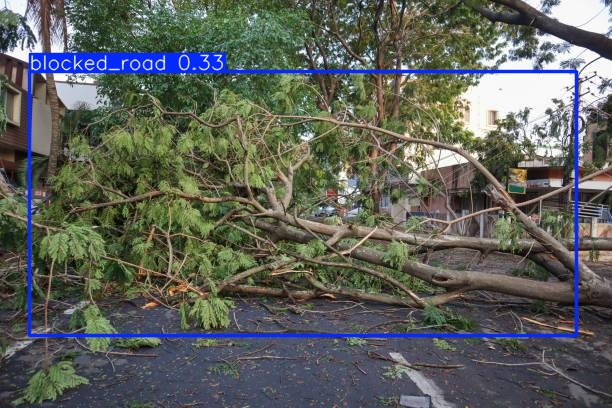

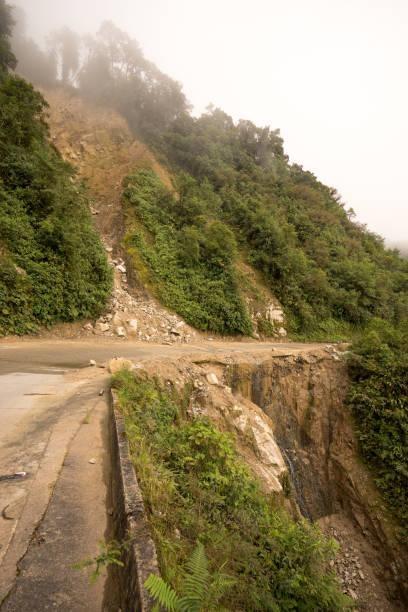

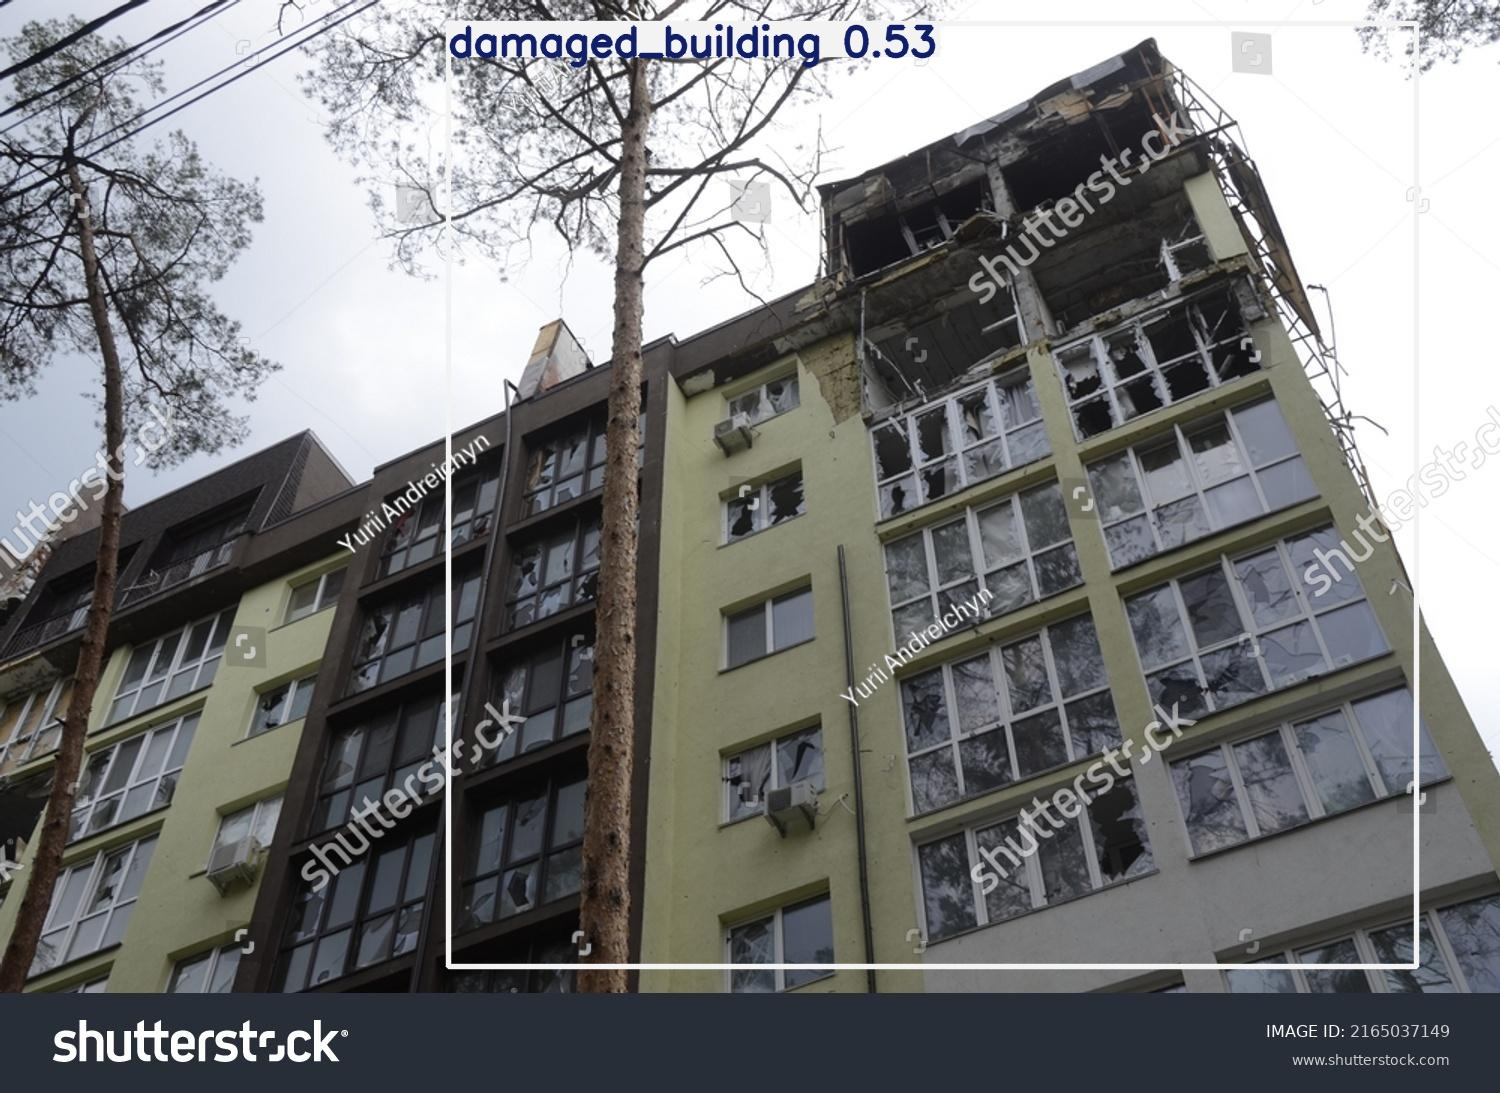

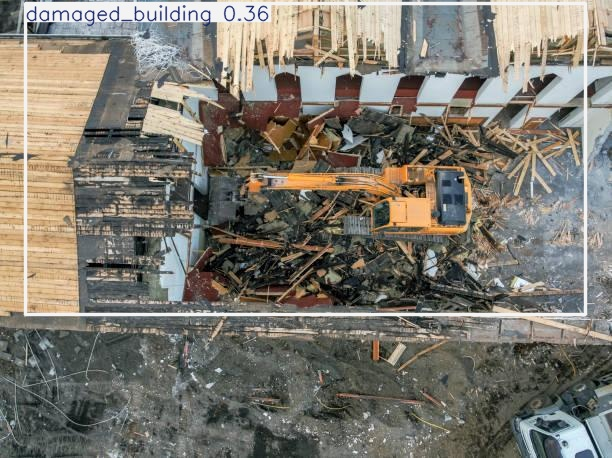

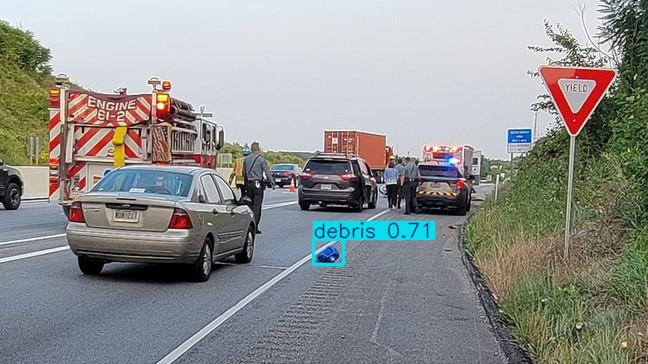

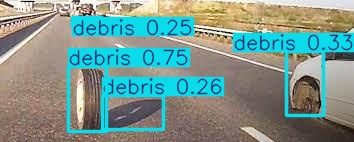

In [ ]:
# Put 5-6 unseen images (or a video) in BASE/demo_inputs first
demo = YOLO(f'{BASE}/finetuned_best.pt')
demo.predict(source=f'{BASE}/demo_inputs', conf=0.25, save=True,
             project=OUT, name='demo', exist_ok=True)

from IPython.display import Image, display
import glob
for f in sorted(glob.glob(f'{OUT}/demo/*.jpg'))[:6]:
    display(Image(f, width=600))

In [ ]:
import yaml, os, ultralytics, torch

for run in ['synthetic', 'finetuned', 'real_only']:
    p = f'{OUT}/{run}/args.yaml'
    if os.path.exists(p):
        a = yaml.safe_load(open(p))
        print(f"{run:10s} | model={a['model']} | epochs={a['epochs']} | patience={a.get('patience')} "
              f"| batch={a['batch']} | imgsz={a['imgsz']} | lr0={a['lr0']} | seed={a['seed']} "
              f"| optimizer={a.get('optimizer')}")
    else:
        print(run, 'args.yaml not found')

print('ultralytics', ultralytics.__version__, '| torch', torch.__version__)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

synthetic  | model=yolov8s.pt | epochs=50 | patience=100 | batch=16 | imgsz=640 | lr0=0.01 | seed=42 | optimizer=auto
finetuned  | model=/content/drive/MyDrive/adverse_weather/synthetic_best.pt | epochs=30 | patience=100 | batch=16 | imgsz=640 | lr0=0.001 | seed=42 | optimizer=auto
real_only  | model=yolov8s.pt | epochs=50 | patience=100 | batch=16 | imgsz=640 | lr0=0.01 | seed=42 | optimizer=auto
ultralytics 8.4.187 | torch 2.11.0+cu130
GPU: Tesla T4


In [ ]:
# Record the settings actually used (for the report)
print('Model: YOLOv8s | imgsz', IMGSZ, '| seed', SEED)
print('Synthetic: 50 epochs, batch 16 | Fine-tune: 30 epochs, lr0=0.001 | Real-only: 50 epochs')
import ultralytics, torch
print('ultralytics', ultralytics.__version__, '| torch', torch.__version__)

Model: YOLOv8s | imgsz 640 | seed 42
Synthetic: 50 epochs, batch 16 | Fine-tune: 30 epochs, lr0=0.001 | Real-only: 50 epochs
ultralytics 8.4.187 | torch 2.11.0+cu130


In [ ]:
import shutil, os
for v in ['val-3', 'val-4', 'val-5', 'val-6']:
    src = f'/content/runs/detect/{v}'
    if os.path.exists(src):
        shutil.copytree(src, f'{OUT}/eval_{v}', dirs_exist_ok=True)
        print('copied', v)
    else:
        print('missing', v)


copied val-3
copied val-4
copied val-5
copied val-6


In [ ]:
from ultralytics import YOLO
for name, w in [('eval_synthetic_on_real', 'synthetic_best.pt'),
                ('eval_finetuned_on_real', 'finetuned_best.pt'),
                ('eval_real_only_on_real', 'real_only_best.pt')]:
    YOLO(f'{BASE}/{w}').val(data=REAL_YAML, split='test', imgsz=IMGSZ, plots=True,
                            project=OUT, name=name, exist_ok=True)

Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1119.0±358.4 MB/s, size: 43.8 KB)
val: Scanning /content/real/real_dataset/labels/test.cache... 146 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 146/146 32.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 3.0it/s 3.4s
                   all        146        327          0          0          0          0
          blocked_road         51         61          0          0          0          0
                debris         28        102          0          0          0          0
      damaged_building         66        164          0          0          0          0
Speed: 3.0ms preprocess, 8.2ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to /content/drive/MyDrive/adve